# 1. Data Upload and Pre-Processing

In [102]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261109

PROJECT_ROOT = Path(".")
RAW_DIR = PROJECT_ROOT / "data_raw"
PROCESSED_DIR = PROJECT_ROOT / "data_processed"
FIGURES_DIR = PROJECT_ROOT / "figures"

PROCESSED_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# Find the timestamped master table automatically
master_files = list(RAW_DIR.glob("Form_552_Master_Table.csv"))
master_files = [
    p for p in master_files
    if "dictionary" not in p.name.lower()
]

assert len(master_files) == 1, (
    f"Expected exactly one master-table CSV, found {len(master_files)}"
)

MASTER_PATH = master_files[0]
DICTIONARY_PATH = RAW_DIR / "Form_552_Master_Table_dictionary.csv"

print("Master table:", MASTER_PATH)
print("Dictionary:", DICTIONARY_PATH)

Master table: data_raw/Form_552_Master_Table.csv
Dictionary: data_raw/Form_552_Master_Table_dictionary.csv


In [103]:
raw = pd.read_csv(MASTER_PATH, low_memory=False)
dictionary = pd.read_csv(DICTIONARY_PATH)

print("Raw shape:", raw.shape)
print("Dictionary shape:", dictionary.shape)

display(raw.head())
display(dictionary.head())

Raw shape: (13298, 54)
Dictionary shape: (54, 4)


,Form552_id,Initial_Submission,Reporting_Co_Is_Affiliate,Reporting_Co_Is_Same_As_Respondent,Resubmission,Date_of_Report,Revision_No,Year_of_Report_End,Principal_Office_Address,Principal_Office_City,...,NextDay_Delivery_Purchases,NextDay_Delivery_Sales,Next_Day_Delivery_Gas_Price_Indices_Purchases,Next_Day_Delivery_Gas_Price_Indices_Sales,Next_Month_Delivery_Gas_Price_Indices_Purchases,Next_Month_Delivery_Purchases,Next_Month_Delivery_Gas_Price_Indices_Sales,Next_Month_Delivery_Sales,SubmssionDate,SubmissionId
0,17399,True,False,True,False,10/28/2026 12:00:00 AM,0,2025,6000 Lakeover Road,Jackson,...,0.0,0.0,0.0,0.0,4.3,0.0,4.3,0.0,10/28/2026 3:44:18 PM,1805815
1,17398,False,False,True,True,10/6/2026 12:00:00 AM,2,2025,"1100 Louisiana Street, Suite 3800",Houston,...,0.4,0.4,23.4,21.4,9.5,0.0,39.4,0.0,10/6/2026 9:57:52 AM,1795614
2,17391,False,False,True,True,9/17/2026 12:00:00 AM,0,2025,375 North Shore Drive,Pittsburgh,...,1.7,0.0,39.7,0.0,31.1,0.0,0.0,0.0,9/17/2026 9:27:11 AM,1791721
3,17388,True,False,True,False,8/13/2026 12:00:00 AM,0,2025,555 17th Street Suite 2400,Denver,...,0.0,0.1,0.0,21.5,0.0,0.0,14.6,3.4,8/13/2026 12:27:56 PM,1783954
4,17387,True,False,True,False,7/31/2026 12:00:00 AM,0,2025,1099 West Front Street,Boise,...,3.2,0.0,0.9,0.0,1.6,0.0,0.0,0.0,8/7/2026 4:53:54 PM,1783157


,Column_Id,Attribute,Description,SQL_Type
0,1,Form552_id,Unique identifier for the FERC Form 552 report.,BIGINT
1,2,Initial_Submission,Indicates if the report is the initial submiss...,BOOLEAN
2,3,Reporting_Co_Is_Affiliate,Represents whether the reporting company is an...,BOOLEAN
3,4,Reporting_Co_Is_Same_As_Respondent,Specifies whether the reporting company is the...,BOOLEAN
4,5,Resubmission,Indicates whether the report is a resubmission...,BOOLEAN


In [104]:
print("Years:")
print(
    raw["Year_of_Report_End"]
    .value_counts()
    .sort_index()
)

print(
    "\nYear range:",
    raw["Year_of_Report_End"].min(),
    "to",
    raw["Year_of_Report_End"].max()
)

blank_reporting_company = (
    raw["Reporting_Company"].isna()
    | raw["Reporting_Company"].astype(str).str.strip().eq("")
)

print("\nRows:", len(raw))
print("Blank Reporting_Company:", blank_reporting_company.sum())
print("Exact duplicate rows:", raw.duplicated().sum())

Years:
Year_of_Report_End
2008    1156
2009     752
2010     755
2011     753
2012     736
2013     731
2014     720
2015     711
2016     746
2017     697
2018     717
2019     714
2020     691
2021     683
2022     693
2023     695
2024     681
2025     667
Name: count, dtype: int64

Year range: 2008 to 2025

Rows: 13298
Blank Reporting_Company: 250
Exact duplicate rows: 0


In [105]:
def normalize_name(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.upper()
    )

filings = raw.copy()

filings["year"] = pd.to_numeric(
    filings["Year_of_Report_End"],
    errors="coerce"
).astype("Int64")

# Reporting_Company is the preferred participant identity.
# Fall back to Respondent only when Reporting_Company is blank.
reporting_name = filings["Reporting_Company"].astype("string").str.strip()

blank_reporting = (
    reporting_name.isna()
    | reporting_name.eq("")
)

filings["company_name"] = reporting_name
filings.loc[blank_reporting, "company_name"] = (
    filings.loc[blank_reporting, "Respondent"]
    .astype("string")
    .str.strip()
)

filings["company_key"] = normalize_name(filings["company_name"])
filings["respondent_key"] = normalize_name(filings["Respondent"])

print("Unique company keys:", filings["company_key"].nunique())
print("Fallback-to-Respondent rows:", blank_reporting.sum())

Unique company keys: 3087
Fallback-to-Respondent rows: 250


In [106]:
filings["revision_no"] = pd.to_numeric(
    filings["Revision_No"],
    errors="coerce"
).fillna(0)

filings["submission_datetime"] = pd.to_datetime(
    filings["SubmssionDate"],
    errors="coerce",
    format="mixed"
)

filing_key = [
    "respondent_key",
    "company_key",
    "year",
]

revision_rows = (
    filings[
        filings.duplicated(filing_key, keep=False)
    ]
    .sort_values(
        filing_key
        + ["revision_no", "submission_datetime", "Form552_id"]
    )
)

print("Rows belonging to duplicate filing keys:", len(revision_rows))
print(
    "Duplicate filing groups:",
    revision_rows.groupby(filing_key).ngroups
)

display(
    revision_rows[
        [
            "Respondent",
            "Reporting_Company",
            "year",
            "Resubmission",
            "Revision_No",
            "SubmssionDate",
            "Form552_id",
        ]
    ]
)

Rows belonging to duplicate filing keys: 10
Duplicate filing groups: 5


,Respondent,Reporting_Company,year,Resubmission,Revision_No,SubmssionDate,Form552_id
12561,City of Duluth,City of Duluth,2008,False,0,6/23/2009 8:59:14 AM,509
13065,City of Duluth,NaN,2008,True,0,7/13/2009 2:28:24 PM,1281
2727,"Clean Energy Future-Lordstown, LLC\n","Clean Energy Future-Lordstown, LLC",2022,False,0,2/8/2023 10:00:18 AM,14545
2711,"Clean Energy Future-Lordstown, LLC","Clean Energy Future-Lordstown, LLC",2022,True,1,2/23/2023 8:52:17 AM,14565
12469,Eastern Shore Natural Gas Company,Eastern Shore Natural Gas Company,2008,False,0,6/25/2009 8:51:19 AM,606
13022,Eastern Shore Natural Gas Company,NaN,2008,True,0,7/15/2009 8:41:54 AM,1324
13067,New York Power Authority,NaN,2008,False,0,4/24/2009 11:37:07 AM,128
12954,New York Power Authority,New York Power Authority,2008,True,1,8/31/2009 2:20:06 PM,1394
11734,Newfield Exploration Company,Newfield Exploration Company,2009,False,0,9/29/2010 10:26:23 AM,1872
11458,Newfield Exploration Company,NaN,2009,True,1,4/29/2011 7:36:24 AM,2700


In [107]:
filings = (
    filings
    .sort_values(
        filing_key
        + ["revision_no", "submission_datetime", "Form552_id"]
    )
    .drop_duplicates(
        subset=filing_key,
        keep="last"
    )
    .reset_index(drop=True)
)

print("Raw rows:", len(raw))
print("Rows after resolving revisions:", len(filings))
print("Rows removed:", len(raw) - len(filings))

Raw rows: 13298
Rows after resolving revisions: 13293
Rows removed: 5


In [108]:
volume_cols = [
    "Volume_TBtu_Purchase",
    "Volume_TBtu_Sales",

    "NextDay_Delivery_Purchases",
    "NextDay_Delivery_Sales",

    "Next_Day_Delivery_Gas_Price_Indices_Purchases",
    "Next_Day_Delivery_Gas_Price_Indices_Sales",

    "Next_Month_Delivery_Purchases",
    "Next_Month_Delivery_Sales",

    "Next_Month_Delivery_Gas_Price_Indices_Purchases",
    "Next_Month_Delivery_Gas_Price_Indices_Sales",

    "As_Physical_Basis_Transactions_Purchases",
    "As_Physical_Basis_Transactions_Sales",

    "NYMEX_Plus_Contracts_Purchases",
    "NYMEX_Plus_Contracts_Sales",
]

for col in volume_cols:
    filings[col] = pd.to_numeric(
        filings[col],
        errors="coerce"
    )

missing_volume = filings[volume_cols].isna().sum()

display(
    missing_volume[missing_volume > 0]
    .sort_values(ascending=False)
    .rename("missing_rows")
    .to_frame()
)

,missing_rows
NextDay_Delivery_Purchases,47
Next_Month_Delivery_Purchases,46
NextDay_Delivery_Sales,43
NYMEX_Plus_Contracts_Purchases,41
NYMEX_Plus_Contracts_Sales,38
Next_Month_Delivery_Sales,36
Next_Day_Delivery_Gas_Price_Indices_Purchases,35
As_Physical_Basis_Transactions_Sales,30
Next_Day_Delivery_Gas_Price_Indices_Sales,29
As_Physical_Basis_Transactions_Purchases,29


In [109]:
filings[volume_cols] = filings[volume_cols].fillna(0.0)

In [110]:
company_year = (
    filings
    .groupby(
        ["company_key", "year"],
        as_index=False
    )[volume_cols]
    .sum()
)

print("Company-year rows:", len(company_year))
display(company_year.head())

Company-year rows: 13110


,company_key,year,Volume_TBtu_Purchase,Volume_TBtu_Sales,NextDay_Delivery_Purchases,NextDay_Delivery_Sales,Next_Day_Delivery_Gas_Price_Indices_Purchases,Next_Day_Delivery_Gas_Price_Indices_Sales,Next_Month_Delivery_Purchases,Next_Month_Delivery_Sales,Next_Month_Delivery_Gas_Price_Indices_Purchases,Next_Month_Delivery_Gas_Price_Indices_Sales,As_Physical_Basis_Transactions_Purchases,As_Physical_Basis_Transactions_Sales,NYMEX_Plus_Contracts_Purchases,NYMEX_Plus_Contracts_Sales
0,(AGGREGATED),2008,73.3,1.1,19.8,0.0,23.4,1.1,0.0,0.0,29.4,0.0,0.0,0.0,0.7,0.0
1,3M COMPANY,2008,8.2,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0,0.0,8.4,0.0,0.0,0.0
2,3M COMPANY,2009,7.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.6,0.0,0.0,0.0
3,3M COMPANY,2010,8.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.4,0.0
4,3M COMPANY,2011,5.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.9,0.0


In [111]:
company_year["total_volume"] = (
    company_year["Volume_TBtu_Purchase"]
    + company_year["Volume_TBtu_Sales"]
)

company_year["purchase_share"] = (
    company_year["Volume_TBtu_Purchase"]
    / company_year["total_volume"]
)

company_year["nextday_fixed_volume"] = (
    company_year["NextDay_Delivery_Purchases"]
    + company_year["NextDay_Delivery_Sales"]
)

company_year["nextday_fixed_share"] = (
    company_year["nextday_fixed_volume"]
    / company_year["total_volume"]
)

company_year["nextday_index_share"] = (
    company_year["Next_Day_Delivery_Gas_Price_Indices_Purchases"]
    + company_year["Next_Day_Delivery_Gas_Price_Indices_Sales"]
) / company_year["total_volume"]

company_year["nextmonth_fixed_share"] = (
    company_year["Next_Month_Delivery_Purchases"]
    + company_year["Next_Month_Delivery_Sales"]
) / company_year["total_volume"]

company_year["nextmonth_index_share"] = (
    company_year["Next_Month_Delivery_Gas_Price_Indices_Purchases"]
    + company_year["Next_Month_Delivery_Gas_Price_Indices_Sales"]
) / company_year["total_volume"]

company_year["physical_basis_share"] = (
    company_year["As_Physical_Basis_Transactions_Purchases"]
    + company_year["As_Physical_Basis_Transactions_Sales"]
) / company_year["total_volume"]

company_year["nymex_plus_share"] = (
    company_year["NYMEX_Plus_Contracts_Purchases"]
    + company_year["NYMEX_Plus_Contracts_Sales"]
) / company_year["total_volume"]

company_year["log_total_volume"] = np.log1p(
    company_year["total_volume"]
)

In [112]:
before = len(company_year)

company_year = company_year[
    company_year["total_volume"] > 0
].copy()

company_year = company_year[
    company_year["nextday_fixed_share"].notna()
].copy()

print("Company-years before:", before)
print("Valid company-years:", len(company_year))
print("Dropped:", before - len(company_year))

Company-years before: 13110
Valid company-years: 12641
Dropped: 469


In [113]:
yearly_cutoffs = (
    company_year
    .groupby("year")["nextday_fixed_share"]
    .quantile(0.75)
    .rename("q75_nextday_share")
)

company_year = company_year.merge(
    yearly_cutoffs,
    on="year",
    how="left"
)

company_year["high_nextday"] = (
    company_year["nextday_fixed_share"]
    >= company_year["q75_nextday_share"]
).astype(int)

year_summary = (
    company_year
    .groupby("year")
    .agg(
        N=("company_key", "size"),
        q75=("q75_nextday_share", "first"),
        positives=("high_nextday", "sum"),
        positive_rate=("high_nextday", "mean"),
    )
)

display(year_summary)

,N,q75,positives,positive_rate
year,,,,
2008,785,0.143314,197,0.250955
2009,724,0.166827,181,0.250000
2010,737,0.185704,185,0.251018
2011,734,0.182685,184,0.250681
2012,722,0.180994,181,0.250693
2013,713,0.152381,179,0.251052
2014,706,0.147189,177,0.250708
2015,686,0.136665,172,0.250729
2016,717,0.129032,180,0.251046


In [114]:
COMPANY_YEAR_PATH = (
    PROCESSED_DIR / "form552_company_year_panel.csv"
)

company_year.to_csv(
    COMPANY_YEAR_PATH,
    index=False
)

print("Saved:", COMPANY_YEAR_PATH)
print("Shape:", company_year.shape)

Saved: data_processed/form552_company_year_panel.csv
Shape: (12641, 28)


# 2. Consecutive-Year Forecasting Sample

In [115]:
# Create next-year labels

future_labels = company_year[
    ["company_key", "year", "high_nextday"]
].copy()

# Shift next year's label backward so that it can merge onto year t
future_labels["year"] = future_labels["year"] - 1

future_labels = future_labels.rename(
    columns={"high_nextday": "target_high_nextday"}
)

# Keep only companies observed in consecutive years
pairs = company_year.merge(
    future_labels,
    on=["company_key", "year"],
    how="inner"
)

pairs["target_year"] = pairs["year"] + 1

print("Consecutive-year prediction rows:", len(pairs))
print(
    "Target-year range:",
    pairs["target_year"].min(),
    "to",
    pairs["target_year"].max()
)

display(pairs.head())

Consecutive-year prediction rows: 9172
Target-year range: 2009 to 2025


,company_key,year,Volume_TBtu_Purchase,Volume_TBtu_Sales,NextDay_Delivery_Purchases,NextDay_Delivery_Sales,Next_Day_Delivery_Gas_Price_Indices_Purchases,Next_Day_Delivery_Gas_Price_Indices_Sales,Next_Month_Delivery_Purchases,Next_Month_Delivery_Sales,...,nextday_index_share,nextmonth_fixed_share,nextmonth_index_share,physical_basis_share,nymex_plus_share,log_total_volume,q75_nextday_share,high_nextday,target_high_nextday,target_year
0,3M COMPANY,2008,8.2,0.0,0.0,0.0,0.2,0.0,0.0,0.0,...,0.024390,0.0,0.000000,1.02439,0.0,2.219203,0.143314,0,0,2009
1,3M COMPANY,2009,7.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,1.00000,0.0,2.151762,0.166827,0,0,2010
2,3M COMPANY,2010,8.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.00000,1.0,2.240710,0.185704,0,0,2011
3,3M COMPANY,2011,5.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.00000,1.0,1.931521,0.182685,0,0,2012
4,"89 ENERGY III, LLC",2021,0.0,6.8,0.0,0.0,0.0,1.9,0.0,0.0,...,0.279412,0.0,0.720588,0.00000,0.0,2.054124,0.079295,0,0,2022


In [116]:
pair_summary = (
    pairs
    .groupby("target_year")
    .agg(
        N_pairs=("company_key", "size"),
        positives=("target_high_nextday", "sum"),
        positive_rate=("target_high_nextday", "mean"),
    )
)

display(pair_summary)

,N_pairs,positives,positive_rate
target_year,,,
2009,510,137,0.268627
2010,569,140,0.246046
2011,577,147,0.254766
2012,562,138,0.245552
2013,562,146,0.259786
2014,563,131,0.232682
2015,539,136,0.252319
2016,550,142,0.258182
2017,537,137,0.255121


In [117]:
CHECKPOINT_YEAR = 2024
FINAL_TEST_YEAR = 2025

development = pairs[
    pairs["target_year"] < CHECKPOINT_YEAR
].copy()

checkpoint = pairs[
    pairs["target_year"] == CHECKPOINT_YEAR
].copy()

final_test = pairs[
    pairs["target_year"] == FINAL_TEST_YEAR
].copy()

print("Development rows:", len(development))
print("Checkpoint rows:", len(checkpoint))
print("Final untouched test rows:", len(final_test))

Development rows: 8101
Checkpoint rows: 529
Final untouched test rows: 542


In [118]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

y_val = checkpoint["target_high_nextday"]

# Persistence: next year's class = this year's class
persistence_pred = checkpoint["high_nextday"]

# Majority rule: predict low for everyone
majority_pred = np.zeros(len(checkpoint), dtype=int)

persistence_error = np.mean(
    persistence_pred != y_val
)

majority_error = np.mean(
    majority_pred != y_val
)

print("Persistence error:", persistence_error)
print("Majority error:", majority_error)

print("\nPersistence confusion matrix:")
print(
    confusion_matrix(
        y_val,
        persistence_pred,
        labels=[1, 0]
    )
)

print(
    "\nPersistence F1:",
    f1_score(y_val, persistence_pred)
)

Persistence error: 0.08695652173913043
Majority error: 0.2665406427221172

Persistence confusion matrix:
[[113  28]
 [ 18 370]]

Persistence F1: 0.8308823529411765


# 3. L2 Logistic Regression Baseline

In [119]:
features = [
    "log_total_volume",
    "purchase_share",
    "nextday_fixed_share",
    "physical_basis_share",
    "nextday_index_share",
    "nextmonth_fixed_share",
    "nextmonth_index_share",
    "nymex_plus_share",
]

print("Number of predictors:", len(features))

display(
    pairs[features]
    .describe()
    .T
)

Number of predictors: 8


,count,mean,std,min,25%,50%,75%,max
log_total_volume,9172.0,3.752075,1.728813,0.262364,2.332144,3.563883,4.808927,9.236271
purchase_share,9172.0,0.646814,0.369081,0.000000,0.472195,0.780034,1.000000,1.000000
nextday_fixed_share,9172.0,0.106202,0.190632,0.000000,0.000000,0.021277,0.131676,1.000000
physical_basis_share,9172.0,0.055941,0.154984,0.000000,0.000000,0.000000,0.027942,1.210526
nextday_index_share,9172.0,0.351360,0.310892,0.000000,0.083333,0.278721,0.534073,1.501197
nextmonth_fixed_share,9172.0,0.042084,0.132815,0.000000,0.000000,0.000000,0.014961,1.000000
nextmonth_index_share,9172.0,0.404338,0.325288,0.000000,0.060846,0.385447,0.669284,1.090909
nymex_plus_share,9172.0,0.029055,0.126457,0.000000,0.000000,0.000000,0.000000,1.000000


In [120]:
feature_audit = pd.DataFrame({
    "missing": pairs[features].isna().sum(),
    "infinite": [
        np.isinf(pairs[c]).sum()
        for c in features
    ],
    "min": pairs[features].min(),
    "max": pairs[features].max(),
})

display(feature_audit)

,missing,infinite,min,max
log_total_volume,0,0,0.262364,9.236271
purchase_share,0,0,0.000000,1.000000
nextday_fixed_share,0,0,0.000000,1.000000
physical_basis_share,0,0,0.000000,1.210526
nextday_index_share,0,0,0.000000,1.501197
nextmonth_fixed_share,0,0,0.000000,1.000000
nextmonth_index_share,0,0,0.000000,1.090909
nymex_plus_share,0,0,0.000000,1.000000


In [121]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

In [122]:
def make_logistic(C):
    return Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "logit",
            LogisticRegression(
                penalty="l2",
                C=C,
                solver="lbfgs",
                max_iter=5000,
                random_state=SEED,
            )
        ),
    ])

In [123]:
VALIDATION_YEARS = list(range(2014, 2024))

print("Forward-validation years:")
print(VALIDATION_YEARS)

for val_year in VALIDATION_YEARS:
    n_train = (
        pairs["target_year"] < val_year
    ).sum()

    n_val = (
        pairs["target_year"] == val_year
    ).sum()

    print(
        f"Train through {val_year - 1}: "
        f"{n_train:4d} rows | "
        f"Validate {val_year}: "
        f"{n_val:3d} rows"
    )

Forward-validation years:
[2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Train through 2013: 2780 rows | Validate 2014: 563 rows
Train through 2014: 3343 rows | Validate 2015: 539 rows
Train through 2015: 3882 rows | Validate 2016: 550 rows
Train through 2016: 4432 rows | Validate 2017: 537 rows
Train through 2017: 4969 rows | Validate 2018: 531 rows
Train through 2018: 5500 rows | Validate 2019: 536 rows
Train through 2019: 6036 rows | Validate 2020: 536 rows
Train through 2020: 6572 rows | Validate 2021: 508 rows
Train through 2021: 7080 rows | Validate 2022: 502 rows
Train through 2022: 7582 rows | Validate 2023: 519 rows


In [124]:
C_GRID = [0.01, 0.1, 1, 10, 100]

cv_results = []

for C in C_GRID:

    for val_year in VALIDATION_YEARS:

        train_fold = pairs[
            pairs["target_year"] < val_year
        ].copy()

        val_fold = pairs[
            pairs["target_year"] == val_year
        ].copy()

        model = make_logistic(C)

        model.fit(
            train_fold[features],
            train_fold["target_high_nextday"]
        )

        val_prob = model.predict_proba(
            val_fold[features]
        )[:, 1]

        ap = average_precision_score(
            val_fold["target_high_nextday"],
            val_prob
        )

        auc = roc_auc_score(
            val_fold["target_high_nextday"],
            val_prob
        )

        cv_results.append({
            "C": C,
            "validation_year": val_year,
            "N": len(val_fold),
            "AP": ap,
            "AUC": auc,
        })

cv_results = pd.DataFrame(cv_results)

display(cv_results.head())

,C,validation_year,N,AP,AUC
0,0.01,2014,563,0.876768,0.950523
1,0.01,2015,539,0.862817,0.941523
2,0.01,2016,550,0.863334,0.937103
3,0.01,2017,537,0.892793,0.955766
4,0.01,2018,531,0.850356,0.928881


In [125]:
cv_summary = (
    cv_results
    .groupby("C")
    .agg(
        mean_AP=("AP", "mean"),
        sd_AP=("AP", "std"),
        mean_AUC=("AUC", "mean"),
        sd_AUC=("AUC", "std"),
    )
    .sort_values("mean_AP", ascending=False)
)

display(cv_summary)

,mean_AP,sd_AP,mean_AUC,sd_AUC
C,,,,
100.00,0.875384,0.024241,0.943893,0.011537
1.00,0.875383,0.024171,0.943846,0.011494
10.00,0.875371,0.024243,0.943881,0.011542
0.10,0.874397,0.024035,0.943092,0.011514
0.01,0.868217,0.023711,0.938759,0.011721


In [126]:
BEST_C = cv_summary.index[0]

print("Selected C:", BEST_C)
print(
    "Mean validation AP:",
    cv_summary.loc[BEST_C, "mean_AP"]
)

Selected C: 100.0
Mean validation AP: 0.87538380567368


In [127]:
oof_parts = []

for val_year in VALIDATION_YEARS:

    train_fold = pairs[
        pairs["target_year"] < val_year
    ].copy()

    val_fold = pairs[
        pairs["target_year"] == val_year
    ].copy()

    model = make_logistic(BEST_C)

    model.fit(
        train_fold[features],
        train_fold["target_high_nextday"]
    )

    val_fold["logit_prob"] = (
        model.predict_proba(
            val_fold[features]
        )[:, 1]
    )

    oof_parts.append(
        val_fold[
            [
                "company_key",
                "target_year",
                "target_high_nextday",
                "logit_prob",
            ]
        ]
    )

oof = pd.concat(
    oof_parts,
    ignore_index=True
)

print("Out-of-fold rows:", len(oof))
display(oof.head())

Out-of-fold rows: 5321


,company_key,target_year,target_high_nextday,logit_prob
0,ABENGOA BIOENERGY COMPANY,2014,0,0.026476
1,ACME BRICK COMPANY,2014,0,0.013964
2,AEP GENERATING COMPANY,2014,1,1.000000
3,AERA ENERGY LLC,2014,0,0.019975
4,AGL RESOURCES INC.,2014,1,0.890473


In [128]:
threshold_grid = np.arange(
    0.05,
    0.61,
    0.01
)

threshold_results = []

for threshold in threshold_grid:

    yearly_errors = []

    for val_year in VALIDATION_YEARS:

        year_data = oof[
            oof["target_year"] == val_year
        ]

        pred = (
            year_data["logit_prob"]
            >= threshold
        ).astype(int)

        error = np.mean(
            pred
            != year_data["target_high_nextday"]
        )

        yearly_errors.append(error)

    threshold_results.append({
        "threshold": threshold,
        "mean_validation_error":
            np.mean(yearly_errors),
    })

threshold_results = pd.DataFrame(
    threshold_results
)

display(
    threshold_results
    .sort_values("mean_validation_error")
    .head(10)
)

,threshold,mean_validation_error
20,0.25,0.095611
19,0.24,0.096156
22,0.27,0.096272
24,0.29,0.097069
23,0.28,0.097230
25,0.30,0.097307
21,0.26,0.097374
18,0.23,0.097810
27,0.32,0.098538
26,0.31,0.098683


In [129]:
BEST_THRESHOLD = (
    threshold_results
    .sort_values(
        "mean_validation_error"
    )
    .iloc[0]["threshold"]
)

print(
    "Selected threshold:",
    BEST_THRESHOLD
)

Selected threshold: 0.25000000000000006


In [130]:
share_features = [
    "purchase_share",
    "nextday_fixed_share",
    "physical_basis_share",
    "nextday_index_share",
    "nextmonth_fixed_share",
    "nextmonth_index_share",
    "nymex_plus_share",
]

share_anomalies = pairs[
    (pairs[share_features] > 1 + 1e-12).any(axis=1)
].copy()

print("Rows with at least one share > 1:", len(share_anomalies))

display(
    share_anomalies[
        ["company_key", "year", "target_year"] + share_features
    ].sort_values(["year", "company_key"])
)

Rows with at least one share > 1: 7


,company_key,year,target_year,purchase_share,nextday_fixed_share,physical_basis_share,nextday_index_share,nextmonth_fixed_share,nextmonth_index_share,nymex_plus_share
0,3M COMPANY,2008,2009,1.000000,0.000000,1.024390,0.024390,0.000000,0.000000,0.000000
5369,NATIONAL PUBLIC GAS AGENCY,2008,2009,0.502439,0.000000,0.000000,0.000000,0.000000,1.004878,0.000000
6227,"PENNECO OIL COMPANY, INC.",2009,2010,0.000000,0.000000,0.000000,0.000000,0.000000,1.041667,0.000000
8685,"VIRGINIA POWER ENERGY MARKETING, INC.",2009,2010,0.547593,0.257492,0.000165,1.501197,0.018823,0.354082,0.149013
3096,"FIRESIDE NATURAL GAS, LLC",2011,2012,0.605263,0.000000,1.210526,0.000000,0.000000,0.000000,0.000000
423,"ARIZONA LNG, LLC",2018,2019,1.000000,0.000000,0.000000,0.090909,0.000000,1.090909,0.000000
424,"ARIZONA LNG, LLC",2019,2020,1.000000,0.000000,0.000000,0.078431,0.000000,1.078431,0.000000


In [131]:
train_final = pairs[
    pairs["target_year"] < CHECKPOINT_YEAR
].copy()

checkpoint_eval = checkpoint.copy()

final_logit = make_logistic(BEST_C)

final_logit.fit(
    train_final[features],
    train_final["target_high_nextday"]
)

checkpoint_eval["logit_prob"] = (
    final_logit.predict_proba(
        checkpoint_eval[features]
    )[:, 1]
)

checkpoint_eval["logit_pred"] = (
    checkpoint_eval["logit_prob"]
    >= BEST_THRESHOLD
).astype(int)

checkpoint_eval["persistence_pred"] = (
    checkpoint_eval["high_nextday"]
    .astype(int)
)

print("Training rows:", len(train_final))
print("Checkpoint rows:", len(checkpoint_eval))
print("C:", BEST_C)
print("Threshold:", BEST_THRESHOLD)

Training rows: 8101
Checkpoint rows: 529
C: 100.0
Threshold: 0.25000000000000006


In [132]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

y_test = checkpoint_eval["target_high_nextday"]

logit_error = np.mean(
    checkpoint_eval["logit_pred"] != y_test
)

persistence_error = np.mean(
    checkpoint_eval["persistence_pred"] != y_test
)

majority_error = np.mean(
    np.zeros(len(checkpoint_eval), dtype=int) != y_test
)

logit_ap = average_precision_score(
    y_test,
    checkpoint_eval["logit_prob"]
)

logit_auc = roc_auc_score(
    y_test,
    checkpoint_eval["logit_prob"]
)

logit_f1 = f1_score(
    y_test,
    checkpoint_eval["logit_pred"]
)

logit_precision = precision_score(
    y_test,
    checkpoint_eval["logit_pred"]
)

logit_recall = recall_score(
    y_test,
    checkpoint_eval["logit_pred"]
)

print(f"Checkpoint N:        {len(checkpoint_eval)}")
print()
print(f"Logistic error:      {logit_error:.4f}")
print(f"Persistence error:   {persistence_error:.4f}")
print(f"Majority error:      {majority_error:.4f}")
print()
print(f"Logistic AP:         {logit_ap:.4f}")
print(f"Logistic AUC:        {logit_auc:.4f}")
print(f"Logistic precision:  {logit_precision:.4f}")
print(f"Logistic recall:     {logit_recall:.4f}")
print(f"Logistic F1:         {logit_f1:.4f}")

Checkpoint N:        529

Logistic error:      0.0851
Persistence error:   0.0870
Majority error:      0.2665

Logistic AP:         0.8759
Logistic AUC:        0.9482
Logistic precision:  0.9068
Logistic recall:     0.7589
Logistic F1:         0.8263


In [133]:
print("Logistic confusion matrix")
print("Rows = true [1, 0], columns = predicted [1, 0]")

print(
    confusion_matrix(
        y_test,
        checkpoint_eval["logit_pred"],
        labels=[1, 0],
    )
)

print("\nPersistence confusion matrix")

print(
    confusion_matrix(
        y_test,
        checkpoint_eval["persistence_pred"],
        labels=[1, 0],
    )
)

Logistic confusion matrix
Rows = true [1, 0], columns = predicted [1, 0]
[[107  34]
 [ 11 377]]

Persistence confusion matrix
[[113  28]
 [ 18 370]]


In [134]:
error_difference = (
    logit_error
    - persistence_error
)

print(
    "Logistic - persistence error:",
    error_difference
)

print(
    "Difference in percentage points:",
    100 * error_difference
)

Logistic - persistence error: -0.0018903591682419701
Difference in percentage points: -0.18903591682419701


In [135]:
BOOTSTRAP_REPS = 10_000

rng = np.random.default_rng(SEED)

boot_differences = []
boot_ap = []

companies = checkpoint_eval[
    "company_key"
].to_numpy()

assert checkpoint_eval["company_key"].is_unique

checkpoint_by_company = (
    checkpoint_eval
    .set_index("company_key")
)

for _ in range(BOOTSTRAP_REPS):

    sampled_companies = rng.choice(
        companies,
        size=len(companies),
        replace=True,
    )

    sample = checkpoint_by_company.loc[
        sampled_companies
    ]

    y_b = sample[
        "target_high_nextday"
    ].to_numpy()

    logit_b = sample[
        "logit_pred"
    ].to_numpy()

    persistence_b = sample[
        "persistence_pred"
    ].to_numpy()

    prob_b = sample[
        "logit_prob"
    ].to_numpy()

    logit_error_b = np.mean(
        logit_b != y_b
    )

    persistence_error_b = np.mean(
        persistence_b != y_b
    )

    boot_differences.append(
        logit_error_b
        - persistence_error_b
    )

    # AP requires both classes to be represented.
    if len(np.unique(y_b)) == 2:
        boot_ap.append(
            average_precision_score(
                y_b,
                prob_b
            )
        )

In [136]:
difference_ci = np.percentile(
    boot_differences,
    [2.5, 97.5]
)

ap_ci = np.percentile(
    boot_ap,
    [2.5, 97.5]
)

print(
    f"Observed logistic - persistence error: "
    f"{100 * error_difference:.2f} pp"
)

print(
    "95% bootstrap CI for error difference: "
    f"[{100 * difference_ci[0]:.2f}, "
    f"{100 * difference_ci[1]:.2f}] pp"
)

print(
    f"\nLogistic AP: {logit_ap:.3f}"
)

print(
    "95% bootstrap CI for AP: "
    f"[{ap_ci[0]:.3f}, "
    f"{ap_ci[1]:.3f}]"
)

Observed logistic - persistence error: -0.19 pp
95% bootstrap CI for error difference: [-1.89, 1.51] pp

Logistic AP: 0.876
95% bootstrap CI for AP: [0.815, 0.929]


In [137]:
checkpoint_predictions_path = (
    PROCESSED_DIR
    / "checkpoint_2024_predictions.csv"
)

checkpoint_eval[
    [
        "company_key",
        "year",
        "target_year",
        "high_nextday",
        "target_high_nextday",
        "logit_prob",
        "logit_pred",
        "persistence_pred",
    ]
].to_csv(
    checkpoint_predictions_path,
    index=False,
)

cv_results.to_csv(
    PROCESSED_DIR / "logistic_forward_cv.csv",
    index=False,
)

threshold_results.to_csv(
    PROCESSED_DIR / "threshold_validation.csv",
    index=False,
)

print("Saved checkpoint outputs.")

Saved checkpoint outputs.


## Modelling Summary

In [138]:
persistence_precision = precision_score(
    y_test,
    checkpoint_eval["persistence_pred"]
)

persistence_recall = recall_score(
    y_test,
    checkpoint_eval["persistence_pred"]
)

persistence_f1 = f1_score(
    y_test,
    checkpoint_eval["persistence_pred"]
)

results_table = pd.DataFrame({
    "Model": [
        "Majority",
        "Persistence",
        "L2 Logistic",
    ],
    "Error Rate": [
        majority_error,
        persistence_error,
        logit_error,
    ],
    "Precision": [
        np.nan,
        persistence_precision,
        logit_precision,
    ],
    "Recall": [
        0.0,
        persistence_recall,
        logit_recall,
    ],
    "F1": [
        0.0,
        persistence_f1,
        logit_f1,
    ],
    "AP": [
        np.nan,
        np.nan,
        logit_ap,
    ],
    "AUC": [
        np.nan,
        np.nan,
        logit_auc,
    ],
})

display(
    results_table.style.format({
        "Error Rate": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "AP": "{:.3f}",
        "AUC": "{:.3f}",
    })
)

,Model,Error Rate,Precision,Recall,F1,AP,AUC
0,Majority,0.267,nan,0.000,0.000,nan,nan
1,Persistence,0.087,0.863,0.801,0.831,nan,nan
2,L2 Logistic,0.085,0.907,0.759,0.826,0.876,0.948


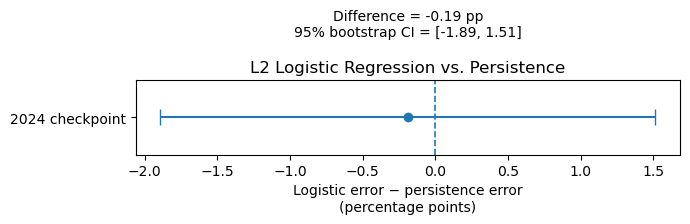

Saved: figures/baseline_error_difference.png


In [139]:
fig, ax = plt.subplots(figsize=(7, 3.5))

point = 100 * error_difference
lower = 100 * difference_ci[0]
upper = 100 * difference_ci[1]

ax.errorbar(
    point,
    0,
    xerr=[
        [point - lower],
        [upper - point],
    ],
    fmt="o",
    capsize=6,
)

ax.axvline(
    0,
    linewidth=1.2,
    linestyle="--",
)

ax.set_yticks([0])
ax.set_yticklabels(["2024 checkpoint"])

ax.set_xlabel(
    "Logistic error − persistence error\n"
    "(percentage points)"
)

ax.set_title(
    "L2 Logistic Regression vs. Persistence"
)

ax.text(
    point,
    0.12,
    (
        f"Difference = {point:.2f} pp\n"
        f"95% bootstrap CI = "
        f"[{lower:.2f}, {upper:.2f}]"
    ),
    ha="center",
)

fig.tight_layout()

figure_path = (
    FIGURES_DIR
    / "baseline_error_difference.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_path)

In [140]:
results_table.to_csv(
    PROCESSED_DIR / "checkpoint_model_comparison.csv",
    index=False,
)

bootstrap_summary = pd.DataFrame({
    "quantity": [
        "logistic_minus_persistence_error_pp",
        "logistic_AP",
    ],
    "estimate": [
        100 * error_difference,
        logit_ap,
    ],
    "ci_2.5": [
        100 * difference_ci[0],
        ap_ci[0],
    ],
    "ci_97.5": [
        100 * difference_ci[1],
        ap_ci[1],
    ],
})

bootstrap_summary.to_csv(
    PROCESSED_DIR / "checkpoint_bootstrap_intervals.csv",
    index=False,
)

display(bootstrap_summary)

,quantity,estimate,ci_2.5,ci_97.5
0,logistic_minus_persistence_error_pp,-0.189036,-1.890359,1.512287
1,logistic_AP,0.875926,0.814850,0.929264
